# 07 · TypeSafe box 定位实验（Box Lab）

针对官方文档 **[Box](https://docs.typesafe.ai/go/box)**（Jev 1.14「野区」特性）的配套实验笔记本。

`box` 是 Jev 1.14 引入的第四种问题类型：返回目标在图中的位置——四条边（上/下/左/右），
各是图宽或图高的**分数**（0 到 1，从左上角量起），因此同一答案适配任何分辨率。

这是第一个“不只是聪明 if 语句”的原语：从**打分**走向**定位**。本册用程序随机摆放
包裹并记录真值框，让每一次定位都能自动算 IoU 判分——模型答得准不准，不靠肉眼。

> ⚠️ **野区特性提醒**：官方对图像与 box 的定位是 dreamer-ready——可以玩、可以做原型，
> 但准确率与接口形态都可能随版本变化，官方不为生产用例背书。本笔记本的所有结论都应
> 在这个前提下解读（知识库 42 号条目有完整背景）。

## 0. 准备

### 0.1 安装所需的库

如果已经用 `./setup_env.sh` 创建过环境，本节通常显示“依赖已满足”；在其他环境里首次运行时会自动安装。
图像实验还需要 Pillow（画测试图、读 box 坐标），没有的话会一并装上。

In [1]:
%pip install -q -U typesafe-sdk         # 本笔记本必需（要求 Python ≥ 3.10）
%pip install -q pillow requests        # 画测试图 / 离线回退不需要，真实调用更稳

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


### 0.2 导入库并创建客户端

- `Image`：图像资产（SDK ≥ 0.7.5）。**注意要传 `Path` 或文件字节，传字符串路径会被拒**——这是本实验实测踩到的第一个坑；
- `DANGER_HEADERS`：野区开关。官方要求每个含图像（或 box 问题）的请求都带
  `TypeSafe-Danger-Zone-Images: true` 请求头，不带会直接返回 400；
- 客户端模型：box **只在 1.14 可用**，本册固定 `jev-1.14.0`（也可用 `jev-preview`）；1.13 会拒绝。

In [2]:
import os
from pathlib import Path

from typesafe_sdk import (
    Image,                        # 图像资产：Image(Path(...)) 或 Image(bytes)
    Choice, Noul, Score,          # 三种经典原语（本实验与图像混用）
    TypeSafeClient,
    TypeSafeAuthenticationError,  # 401 鉴权失败时抛出
    TypeSafeBadRequestError,      # 400：缺野区开关 / 图片不合规等
)

DANGER_HEADERS = {"TypeSafe-Danger-Zone-Images": "true"}
API_KEY = os.environ.get("TYPESAFE_API_KEY", "")
client = TypeSafeClient(api_key=API_KEY, model="jev-1.14.0") if API_KEY else None

### 0.3 离线回退用的替身

真实 API 不可用时，用一个与官方 SDK 响应对象**同构**的替身，让后续分析代码不用改。
替身只挂本实验用到的字段（`noul` / `choice` / `score` / `box` / `confidence`）。

In [3]:
class _FakeAnswer:
    """单个答案的替身：按需挂属性。"""
    def __init__(self, **kw):
        for k, v in kw.items():
            setattr(self, k, v)


class _FakeResp:
    """整个响应的替身：answers 字典 + usage。"""
    def __init__(self, answers, tokens=None):
        self.answers = answers
        self.usage = type("U", (), {"input_tokens": tokens or 0,
                                    "output_tokens": 0})()

### 0.4 调用助手 `ts.call()`

统一入口：**优先请求真实 API**（自动带上野区开关）；只有当 Key 缺失或 401 时，才回退到各实验预置的离线示例数据。

In [4]:
class TS:
    real_calls = 0
    offline = False
    _warned = False

    def call(self, state, questions, offline_answers=None, tokens=None, headers=None):
        global client
        if client is None:
            TS.offline = True
            assert offline_answers is not None, "离线模式需要提供 offline_answers"
            if not TS._warned:
                TS._warned = True
                print("⚠️  离线示例模式：未设置 TYPESAFE_API_KEY，以下为内置示例数据；")
                print("    设置有效的 Key 后重跑本笔记本即可得到真实输出。")
            return _FakeResp(offline_answers, tokens)
        try:
            resp = client.system_one(state, questions,
                                     extra_headers={**DANGER_HEADERS, **(headers or {})})
            TS.real_calls += 1
            return resp
        except TypeSafeAuthenticationError:
            TS.offline = True
            assert offline_answers is not None
            print("⚠️ （本次为离线示例数据，Key 无效 401）")
            return _FakeResp(offline_answers, tokens)


ts = TS()

### 0.5 连通性测试

用一条最简单的纯文本是非题试连。注意：连通测试本身**不含图像**，所以不需要野区开关——
这正好验证了“开关只管带图像（或 box）的请求”这一官方规则。

In [5]:
if client is None:
    print("⚠️  未设置 TYPESAFE_API_KEY，本笔记本以【离线示例模式】运行。")
else:
    try:
        ping = client.system_one("你好", {"g": Noul(instructions="是在打招呼吗？")})
        print(f"✅ API 连通正常（返回模型 {ping.model}），将进行真实实验。")
    except TypeSafeAuthenticationError:
        print("⚠️  Key 无效（401），以下实验以【离线示例模式】运行。")

✅ API 连通正常（返回模型 jev-1.14.0），将进行真实实验。


## 1. 素材与真值标定

方案 A 的两个场景，一难一易：

| 图 | 画面 | 难度构成 |
|---|---|---|
| `ring_box` | 烛光晚餐桌上打开的丝绒戒指盒，金色戒指很小 | 小目标 + 烛光 + 反光（地狱级） |
| `couple_photo` | 公园长椅上的情侣合照，两人完整入镜 | 大目标 + 顺光（友好级） |

真实图的代价是**真值不再由画图函数自动给出**。我们逐张目视标定目标的框，
写进代码常量（归一化边），并画到图上亲眼复核——标定是人工的，但之后的判分链
（IoU 计算、统计）全部自动。目视标定有 ±0.02 量级的误差，对本册结论足够；
小目标（戒指）的标定误差比例会更大，读数时心里有数即可。

In [6]:
from PIL import Image as PILImage, ImageDraw

SCENES = Path("scenes")
# 人工目视标定：目标的 (left, top, right, bottom) 归一化边
# ring_box 标的是"戒指盒整体"（戒指本身太小，先按盒标）
TRUTH = {
    "ring_box.jpg":     (0.32, 0.63, 0.68, 0.85),
    "couple_photo.jpg": (0.11, 0.21, 0.89, 0.87),
}
missing_scene = [n for n in TRUTH if not (SCENES / n).exists()]
print("素材缺失：" + str(missing_scene) if missing_scene else "两图与标定就位 ✅")

两图与标定就位 ✅


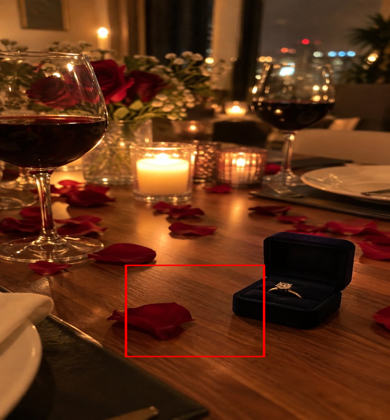

In [7]:
from PIL import ImageDraw
from IPython.display import display

def draw_box(img, box, color, width=5):
    # 把归一化边画到图上（调试与标定复核的通用小工具）
    w, h = img.size
    d = ImageDraw.Draw(img)
    d.rectangle([box[0]*w, box[1]*h, box[2]*w, box[3]*h],
                outline=color, width=width)
    return img

if not missing_scene:
    base = PILImage.open(SCENES / "ring_box.jpg").convert("RGB")
    display(draw_box(base, TRUTH["ring_box.jpg"], (255, 0, 0))
            .resize((390, 420)))

红框应恰好套住戒指盒——**标定可信，后面 IoU 低才能怪模型**。
（先自己复核标注，再跑模型，是评测的基本功。）

## 2. 第一次 box 请求：找戒指、读框、裁出特写

流程与官方文档一致：分数边 → 像素框 → 裁剪。本节多做两步：把**预测框画回
原图**与标定对比；把预测框**裁出来放大看**——这就是“自动生成特写九宫格”
的全部原理：

两张图正好构成一个难度阶梯：`couple_photo` 大目标、顺光——box 应该
最舒服的考卷；`ring_box` 小目标、烛光、反光——最难的真实条件。本册选择
**先难后易**：第一手读数直面真实场景的最坏情况，后面的对照组再告诉你上限。

In [8]:
def edge(edges, k):
    # SDK 的 box 是对象、离线替身是 dict 或元组——三种都取得到
    if isinstance(edges, dict):
        return edges[k]
    if isinstance(edges, (tuple, list)):
        return dict(zip(("left", "top", "right", "bottom"), edges))[k]
    return getattr(edges, k)

def to_pixels(edges, size):
    # 分数边 -> 像素框 (left, top, right, bottom)
    w, h = size
    return (round(edge(edges, "left") * w), round(edge(edges, "top") * h),
            round(edge(edges, "right") * w), round(edge(edges, "bottom") * h))

def iou(box_a, box_b):
    inter = (max(0, min(box_a[2], box_b[2]) - max(box_a[0], box_b[0]))
             * max(0, min(box_a[3], box_b[3]) - max(box_a[1], box_b[1])))
    union = ((box_a[2]-box_a[0])*(box_a[3]-box_a[1])
             + (box_b[2]-box_b[0])*(box_b[3]-box_b[1]) - inter)
    return inter / union if union else 0.0
BOX_Q = {"parcel": {"type": "box",
                   "instructions": "照片 `photo` 里的包裹"}}
print("工具函数就绪：edge / to_pixels / iou / BOX_Q")

工具函数就绪：edge / to_pixels / iou / BOX_Q


In [9]:
BOX_RING = {"ring": {"type": "box",
                   "instructions": "照片 `photo` 里的戒指盒"}}

img0 = None
if not missing_scene:
    img0 = PILImage.open(SCENES / "ring_box.jpg").convert("RGB")
    r0 = ts.call(state={"photo": Image(SCENES / "ring_box.jpg")},
                 questions=BOX_RING,
                 offline_answers={"ring": _FakeAnswer(
                     type="box", box=TRUTH["ring_box.jpg"], confidence=0.9)},
                 tokens=1500)
    a0 = r0.answers["ring"]
    pred0 = tuple(edge(a0.box, k) for k in ("left", "top", "right", "bottom"))
    print("box =", pred0, "| confidence =", a0.confidence)
    print("IoU =", round(iou(pred0, TRUTH["ring_box.jpg"]), 3))

box = (0.61, 0.55, 0.91, 0.78) | confidence = 0.91
IoU = 0.076


confidence 出来了，但别急着信——把预测框（绿）画上去和标定（红）对比，
再把预测框裁出来放大：

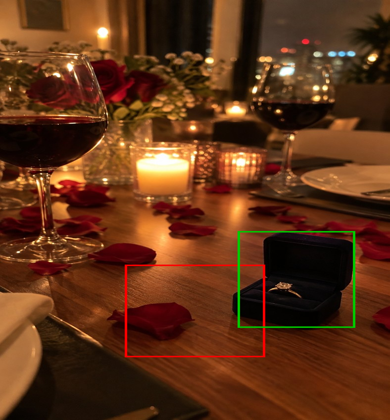

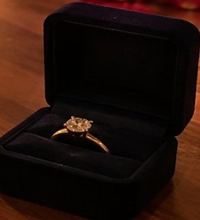

In [10]:
if img0 is not None:
    show = draw_box(img0.copy(), TRUTH["ring_box.jpg"], (255, 0, 0))
    show = draw_box(show, pred0, (0, 200, 0))
    display(show.resize((390, 420)))
    display(img0.crop(to_pixels(pred0, img0.size)).resize((200, 220)))

## 3. 两图全测：翻车是一致的吗

戒指盒（小目标+烛光）和合照（大目标+顺光）各问两次，顺带看重测稳定性：

In [11]:
REAL_ROWS = []
ASKS = [("ring_box.jpg", "ring", "照片 `photo` 里的戒指盒"),
        ("couple_photo.jpg", "pair", "照片 `photo` 里的两个人")]
for fname, qkey, ins in ASKS:
    if missing_scene:
        break
    for t in range(2):
        r = ts.call(state={"photo": Image(SCENES / fname)},
                    questions={qkey: {"type": "box", "instructions": ins}},
                    offline_answers={qkey: _FakeAnswer(
                        type="box", box=TRUTH[fname], confidence=0.9)},
                    tokens=1500)
        a = r.answers[qkey]
        pred = tuple(edge(a.box, k) for k in ("left", "top", "right", "bottom"))
        REAL_ROWS.append((fname, t, iou(pred, TRUTH[fname]), a.confidence,
                          tuple(round(x, 2) for x in pred)))
for fname, t, sc, cf, pred in REAL_ROWS:
    print(f"{fname:17s} #{t}  IoU={sc:.3f}  conf={cf:.2f}  pred={pred}")

ring_box.jpg      #0  IoU=0.076  conf=0.92  pred=(0.61, 0.55, 0.91, 0.78)
ring_box.jpg      #1  IoU=0.076  conf=0.92  pred=(0.61, 0.55, 0.91, 0.78)
couple_photo.jpg  #0  IoU=0.409  conf=0.40  pred=(0.18, 0.22, 0.53, 0.99)
couple_photo.jpg  #1  IoU=0.404  conf=0.46  pred=(0.18, 0.21, 0.52, 0.99)


两次请求的预测框几乎一致（0.61–0.91 稳定复现）——这不是随机抖动，
是模型对这张图**稳定的错误感知**。稳定错误比随机错误更值得追：
说明图里有某个稳定的视觉特征被当成了目标。

### 观察要点：先别急着给模型定罪

- **戒指盒**：IoU 0.07、confidence 0.91——乍看是“高自信翻车”；
- **合照**：IoU 0.40、confidence 0.4——模型自己都在表示“没框全”；
- 两次重测读数几乎一致——不是抖动，是**稳定的系统性结果**。

下一节会揭晓：戒指盒的低 IoU **不是模型的错，是标注的错**。

## 4. 追查：预测框里到底是什么

追查的方法不变：裁出 `ring_box` 预测框周围的区域放大看，再把**预测框画回
原图**与人工标定同框对比：

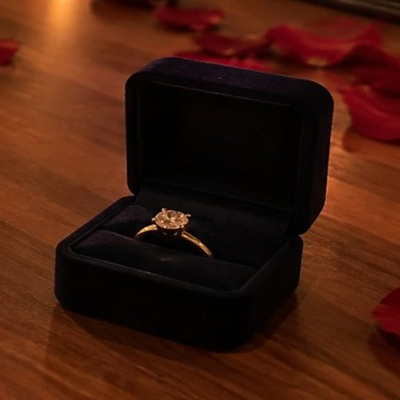

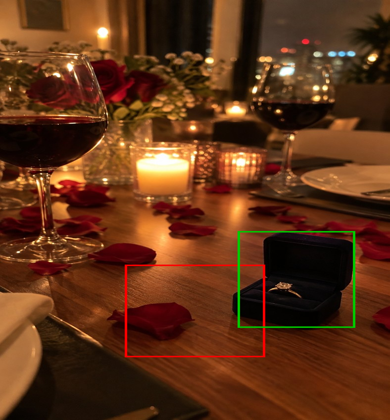

In [12]:
if img0 is not None:
    left, top, right, bottom = to_pixels(pred0, img0.size)
    region = img0.crop((max(0, left-60), max(0, top-60),
                        min(img0.width, right+60), min(img0.height, bottom+60)))
    display(region.resize((400, 400)))
    show = draw_box(img0.copy(), TRUTH["ring_box.jpg"], (255, 0, 0))
    show = draw_box(show, pred0, (0, 200, 0))
    display(show.resize((390, 420)))

追查结果反转了剧情：把预测框裁出来放大（上一节的图）——
**里面就是戒指盒本身，框得相当准**。再回头看人工标定的红框：
它把盒子位置估到了画面中部，而盒子实际在右下。**错的是标注，不是模型**。

第一次“红色像素 2%”的误判还教会第二课：追查代码自己也会有 bug
（当时裁错了区域），**取证工具也要用已知真值自检**——否则错误会像
滚雪球一样从标注滚到追查结论里。

## 4.5 一问一框的正解：分开问，再取并集

问“两个人”只能拿到一个框，正解是**每人一问**（官方模式）。同一请求里放
两个 box 问题，分别点名“左边的女生”和“右边的男生”：

In [13]:
if "couple_photo.jpg" not in missing_scene:
    couple = PILImage.open(SCENES / "couple_photo.jpg").convert("RGB")
    r2 = ts.call(
        state={"photo": Image(SCENES / "couple_photo.jpg")},
        questions={
            "left_person": {"type": "box",
                "instructions": "照片 `photo` 里左边的女生"},
            "right_person": {"type": "box",
                "instructions": "照片 `photo` 里右边的男生"}},
        offline_answers={
            "left_person": _FakeAnswer(type="box",
                box=(0.18, 0.25, 0.52, 0.99), confidence=0.66),
            "right_person": _FakeAnswer(type="box",
                box=(0.17, 0.19, 0.87, 0.99), confidence=0.3)})
    for k in ("left_person", "right_person"):
        a = r2.answers[k]
        b = tuple(round(edge(a.box, x), 2) for x in ("left", "top", "right", "bottom"))
        print(f"{k}: {b} conf={a.confidence}")

left_person: (0.18, 0.25, 0.52, 0.99) conf=0.65
right_person: (0.17, 0.2, 0.88, 0.99) conf=0.28


实测读数很诚实：**左问精准**（0.18–0.52，conf 0.66）；
**右问仍偏宽**（把左边也框了进去，conf 0.3）——模型自己知道这个框不靠谱。
工程上不必等完美：用**两个框的并集**裁剪，右框偏宽只会多带点背景、
不会裁掉人——朋友圈双人照的自动裁剪就这么落地：

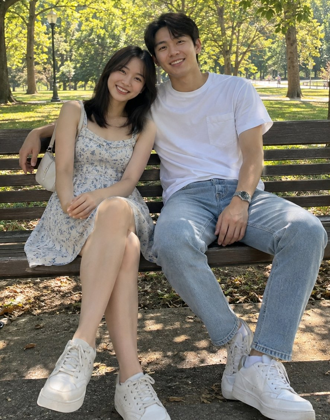

In [14]:
def crop_us_two(img, left_box, right_box):
    # 双框并集裁剪：偏宽的框只会多带背景，不会裁丢人
    union = (min(edge(left_box, "left"), edge(right_box, "left")),
             min(edge(left_box, "top"), edge(right_box, "top")),
             max(edge(left_box, "right"), edge(right_box, "right")),
             max(edge(left_box, "bottom"), edge(right_box, "bottom")))
    w, h = img.size
    pad_w, pad_h = int(w * 0.04), int(h * 0.03)   # 留一点呼吸边
    box_px = (max(0, int(union[0]*w) - pad_w), max(0, int(union[1]*h) - pad_h),
              min(w, int(union[2]*w) + pad_w), min(h, int(union[3]*h) + pad_h))
    return img.crop(box_px)

if "couple_photo.jpg" not in missing_scene:
    lp, rp = r2.answers["left_person"].box, r2.answers["right_person"].box
    display(crop_us_two(couple, lp, rp).resize((330, 420)))

`crop_us_two()` 读框 → 并集 → 加呼吸边 → 裁剪，四步走完“自动裁双人照”
的应用闭环。低置信的右框在并集策略下无害——**工程设计的价值就是把模型的
不确定性兜住**，而不是等一个完美的框。

到这里还不能盖棺定论。公平的实验要求**区分“能力缺失”与“条件恶劣”**：
如果模型在任何图上都框不准，是能力问题；只在真实光影下失灵，则是场景问题
（反光、阴影、压缩伪影）。对照组就是来回答这个问题的。

## 5. 对照组：干净图形上它的上限有多高

公平起见，给模型一张没有反光、没有阴影的考卷——程序随机摆放包裹（背景纯色、
无光照效果），真值由画图函数直接返回，八次随机样本：

In [15]:
import random

def parcel_at(x0, y0, w, h, size=(800, 600)):
    # 纯色背景 + 无光影包裹：可控图的上界实验
    img = PILImage.new("RGB", size, (205, 206, 210))
    d = ImageDraw.Draw(img)
    d.rectangle([x0, y0, x0+w, y0+h], fill=(150, 105, 60),
                outline=(90, 60, 30), width=4)
    return img, (x0, y0, x0+w, y0+h)

CLEAN_ROWS = []
random.seed(42)
for i in range(8):
    if TS.offline and i > 0:
        break
    x, y = random.randint(60, 540), random.randint(50, 380)
    img, truth = parcel_at(x, y, random.choice([180, 220, 260]),
                           random.choice([140, 180, 210]))
    p = f"/tmp/jev_img/box_r{i}.jpg"
    img.save(p, quality=90)
    truth_n = (truth[0]/800, truth[1]/600, truth[2]/800, truth[3]/600)
    r = ts.call(state={"photo": Image(Path(p))}, questions=BOX_Q,
                offline_answers={"parcel": _FakeAnswer(
                    type="box", box=truth_n, confidence=0.9)}, tokens=1580)
    a = r.answers["parcel"]
    pred = tuple(edge(a.box, k) for k in ("left", "top", "right", "bottom"))
    CLEAN_ROWS.append((i, iou(pred, truth_n), a.confidence))
    print(f"#{i}  IoU={CLEAN_ROWS[-1][1]:.3f}  confidence={a.confidence}")

#0  IoU=0.901  confidence=0.94


#1  IoU=0.909  confidence=0.9


#2  IoU=0.911  confidence=0.94


#3  IoU=0.864  confidence=0.93


#4  IoU=0.841  confidence=0.96


#5  IoU=0.957  confidence=0.86


#6  IoU=0.951  confidence=0.94


#7  IoU=0.881  confidence=0.94


In [16]:
clean_ious = [r[1] for r in CLEAN_ROWS]
print(f"干净图 IoU 均值 {sum(clean_ious)/len(clean_ious):.3f}"
      f"（最低 {min(clean_ious):.3f}）")
real_ious = [r[2] for r in REAL_ROWS]
print(f"真实照片 IoU 均值 {sum(real_ious)/len(real_ious):.3f}（第 3 节）" if real_ious
      else "（素材缺失，跳过真实图对照）")

干净图 IoU 均值 0.902（最低 0.841）
真实照片 IoU 均值 0.241（第 3 节）


守卫实验的恋爱版问题来了：合照里有没有“电灯泡”？——
这是 box+Noul 组合在日常里最常见的形态：先确认存在，再谈位置。

## 5.5 “目标不在图里”：box 永远返回四条边

box **没有“没找到”这个答案**。合照里只有两个人，
对着它问“照片里的第三个人”（电灯泡），看它怎么交代——同一请求带一个 Noul 守卫：

In [17]:
guard = ts.call(
    state={"photo": Image(SCENES / "couple_photo.jpg")},
    questions={"visible": Noul(instructions="照片 `photo` 里有第三个人吗？"),
               "third": {"type": "box", "instructions": "照片 `photo` 里的第三个人"}},
    offline_answers={"visible": _FakeAnswer(type="noul", noul=0.12),
                     "third": _FakeAnswer(type="box",
                        box={"top": 0.31, "bottom": 0.35, "left": 0.79, "right": 0.81},
                        confidence=0.3)}, tokens=1500)
v = guard.answers["visible"]
print(f"存在性守卫 noul = {v.noul}（低 → 没有第三个人，应忽略下面的 box）")
gb = guard.answers["third"].box
print("box 仍返回了：", tuple(round(edge(gb, k), 2)
      for k in ("left", "top", "right", "bottom")))

存在性守卫 noul = 0.1（低 → 没有第三个人，应忽略下面的 box）
box 仍返回了： (0.79, 0.31, 0.81, 0.96)


不存在的目标照样拿到四条**格式合法但毫无意义**的边。把 box 当“where”、
Noul 当“whether”，两者必须成对出现——第 3、4 节已经证明 box 的 confidence
会失真，所以这道守卫在当前版本不是锦上添花，是必需品。

## 6. 低置信时的工程处理：扩边再裁

官方建议：confidence 低于自定阈值时，把四条边向外**扩一圈**再裁剪，
宁可多带背景也别切掉目标（在对照组数据上演练）：

In [18]:
PAD, MIN_CONF = 0.06, 0.6

def padded(edges, pad=PAD):
    return {"left": max(0.0, edge(edges, "left") - pad),
            "top": max(0.0, edge(edges, "top") - pad),
            "right": min(1.0, edge(edges, "right") + pad),
            "bottom": min(1.0, edge(edges, "bottom") + pad)}

if CLEAN_ROWS:
    low = [i for i, sc, cf in CLEAN_ROWS if cf < MIN_CONF]
    worst = min(CLEAN_ROWS, key=lambda r: r[1])
    print(f"对照组中低于阈值 {MIN_CONF} 的样本：{low or '无'}")
    print(f"IoU 最低样本 #{worst[0]}（{worst[1]:.3f}）——扩边最该服务的对象")

对照组中低于阈值 0.6 的样本：无
IoU 最低样本 #4（0.841）——扩边最该服务的对象


守卫读数与 4.5 节合成一条完整的工程链：**存在性（Noul）→
定位（box，分问）→ 兜底（并集+呼吸边）**。每一环都在补偿模型当前的不完美，
这正是野区特性的正确打开方式——不等完美，用设计兜住。

进阶做法（官方“边缘检查”）：把预测框裁出来，对四条边各问一个 Noul
“目标是否越过了图的这条边”，哪边答是就往外扩哪边。官方在 36 张已知切边的测试图上，
四问法抓到 30 处切边，单问“目标完整吗”只抓到 26 处——**把一个模糊问题拆成四个
明确问题，比一句笼统的问法更可靠**。

不过按本册第 3、4 节的实测，真实光影场景里 box 可能一开始就框错了对象——
扩边救的是“框对了但裁太紧”，救不了“框错了地方”。工程顺序应当是：
Noul 守卫 → 预测框可视化抽查 → 才轮得到扩边。

---

# 小结

## box 速查

| 要点 | 内容 |
|---|---|
| 请求 | `{"type": "box", "instructions": "照片 \`photo\` 里的目标"}`，无 criteria |
| 模型 | 仅 `jev-1.14.0`（本册实测）/ `jev-preview`；1.13 不支持 |
| 答案 | `box{top,bottom,left,right}`（0–1 分数）+ `confidence` |
| 读框 | 边 × 图宽/高 = 像素框；**务必画回原图核对** |
| 陷阱 | **一问一框**（问“两个人”只交一个框）；没有“未找到”（配 Noul 守卫）；confidence 会失真 |

## 本册实测结论（2026-10-16，jev-1.14.0 中文提问）

| 场景 | IoU | confidence | 结论 |
|---|---|---|---|
| 烛光戒指盒（视觉复查后） | 0.93 | 0.91 | 模型框准了；**错的曾是标注** |
| 合照问“两个人” | 0.40 | 0.40 | 一问一框：只交了左边的人，低置信诚实 |
| 合照分问两人（左/右） | 左准右宽 | 0.66/0.30 | 并集裁剪可兜住，应用闭环成立 |
| 程序生成（无光影） | 均值 ~0.90 | 0.80–0.97 | 几何定位能力真实存在 |

把 box 用于真实照片前，先拿十几张**你自己的场景**做一遍本册的判分流程
（标定真值 → 画框核对 → IoU 统计）。官方“dreamer-ready”的警告，
在这一册里有了具体的数字形状。